# Checks archived from `t_scooby_bridge.ipynb`

These cells were moved out of the tutorial `epione_guide/tutorials/single/t_scooby_bridge.ipynb` so that it focuses on the application. Outputs are the ones stored when the tutorial was last executed. The cells use names defined in the tutorial; run them after the tutorial's earlier cells.

Run them after the tutorial's Parts 1–4 (they use `reader`, `groups`, `names`, `W0`, `T`, `x`, `C`, `bc_to_idx`, `n_frag`) and its cell that loads upstream scooby from `SCOOBY_SRC` (defines `HAVE_UPSTREAM` and imports `onTheFlyMultiomeDataset`). Automated versions: `tests/test_scooby_parity.py` and `tests/test_scooby_model.py`.

## Part 5 · Numerical parity with upstream

Shapes agreeing proves nothing. This section builds the genome-wide
insertion matrix upstream expects, hands it to **upstream's own**
`onTheFlyMultiomeDataset._load_pseudobulk`, and requires the result to be
identical to the reader's.

Only chr19 is materialised, and `reference_sequences` is set to chr19
alone so upstream's concatenated-coordinate offset is zero — that isolates
its slicing/trimming/binning arithmetic from bookkeeping.

In [12]:
%%time
if HAVE_UPSTREAM:
    import scipy.sparse as sp
    import anndata as ad

    L = chrom_sizes[CHROM]
    rows_i, cols_i, starts_seen = [], [], set()
    collisions = 0
    tbx = pysam.TabixFile(str(FRAG))
    for line in tbx.fetch(CHROM):
        f = line.split('\t')
        i = bc_to_idx.get(f[3])
        if i is None:
            continue
        s, e = int(f[1]), int(f[2])
        # Upstream's container stores one fragment length per
        # (cell, start); count how often real data would collide.
        if (i, s) in starts_seen:
            collisions += 1
        else:
            starts_seen.add((i, s))
        for p in (s, e):
            if 0 <= p < L:
                rows_i.append(i); cols_i.append(p)
    tbx.close()

    ins = sp.coo_matrix(
        (np.ones(len(rows_i), np.float32),
         (np.asarray(rows_i, np.int64), np.asarray(cols_i, np.int64))),
        shape=(reader.n_cells, L)).tocsr()
    ins.sum_duplicates()

    adata = ad.AnnData(X=sp.csr_matrix((reader.n_cells, 0), dtype=np.float32))
    adata.obs_names = [b + '-1' for b in reader.barcodes]
    adata.obsm['insertion'] = ins
    adata.uns['reference_sequences'] = pd.DataFrame(
        {'reference_seq_name': [CHROM], 'reference_seq_length': [L]})

    print(f'insertion matrix {ins.shape}, {ins.nnz:,} non-zero positions')
    print(f'(cell, start) collisions in real data: {collisions:,} of '
          f'{n_frag:,} fragments ({100 * collisions / n_frag:.2f}%) — '
          'fragments upstream\'s fragment_paired container cannot hold '
          'separately. Built here directly from fragments to avoid the issue.')

insertion matrix (7131, 61431566), 5,677,064 non-zero positions
(cell, start) collisions in real data: 3,888 of 2,856,209 fragments (0.14%) — fragments upstream's fragment_paired container cannot hold separately. Built here directly from fragments to avoid the issue.
CPU times: user 4.7 s, sys: 291 ms, total: 4.99 s
Wall time: 4.99 s


In [13]:
# Runs upstream's own _load_pseudobulk for an ATAC-only setup.
def upstream_profile(chrom, t_start, t_end, groups, crl=90):
    ds = object.__new__(onTheFlyMultiomeDataset)
    ds.adatas = {'atac': adata}
    ds.normalize_atac = True
    ds.clip_soft = 5
    ds.custom_read_length = crl
    cs = adata.uns['reference_sequences'].copy()
    cs['offset'] = np.insert(cs['reference_seq_length'].cumsum()[:-1].values, 0, 0)
    ds.chrom_sizes = cs.set_index('reference_seq_name').to_dict('index')

    size = ds.chrom_sizes[chrom]
    c0, c1 = size['offset'], size['reference_seq_length']
    s = int(max(0, t_start - (crl + 10))) + c0
    e = int(min(t_end + (crl + 10), c1)) + c0
    gd = [size, c0, c1, s, e, t_start, t_end]
    return np.vstack([ds._load_pseudobulk(list(g), gd).numpy().ravel()
                      for g in groups])


if HAVE_UPSTREAM:
    up = upstream_profile(CHROM, W0, W0 + T, groups)
    mine = reader.pseudobulk(CHROM, W0, W0 + T, groups)
    diff = np.abs(up - mine)
    print('upstream', up.shape, ' epione', mine.shape)
    print(f'max|diff| = {diff.max():.10g}     mean|diff| = {diff.mean():.10g}')
    print('IDENTICAL' if diff.max() == 0 else 'MISMATCH')

upstream (4, 6144)  epione (4, 6144)
max|diff| = 0     mean|diff| = 0
IDENTICAL


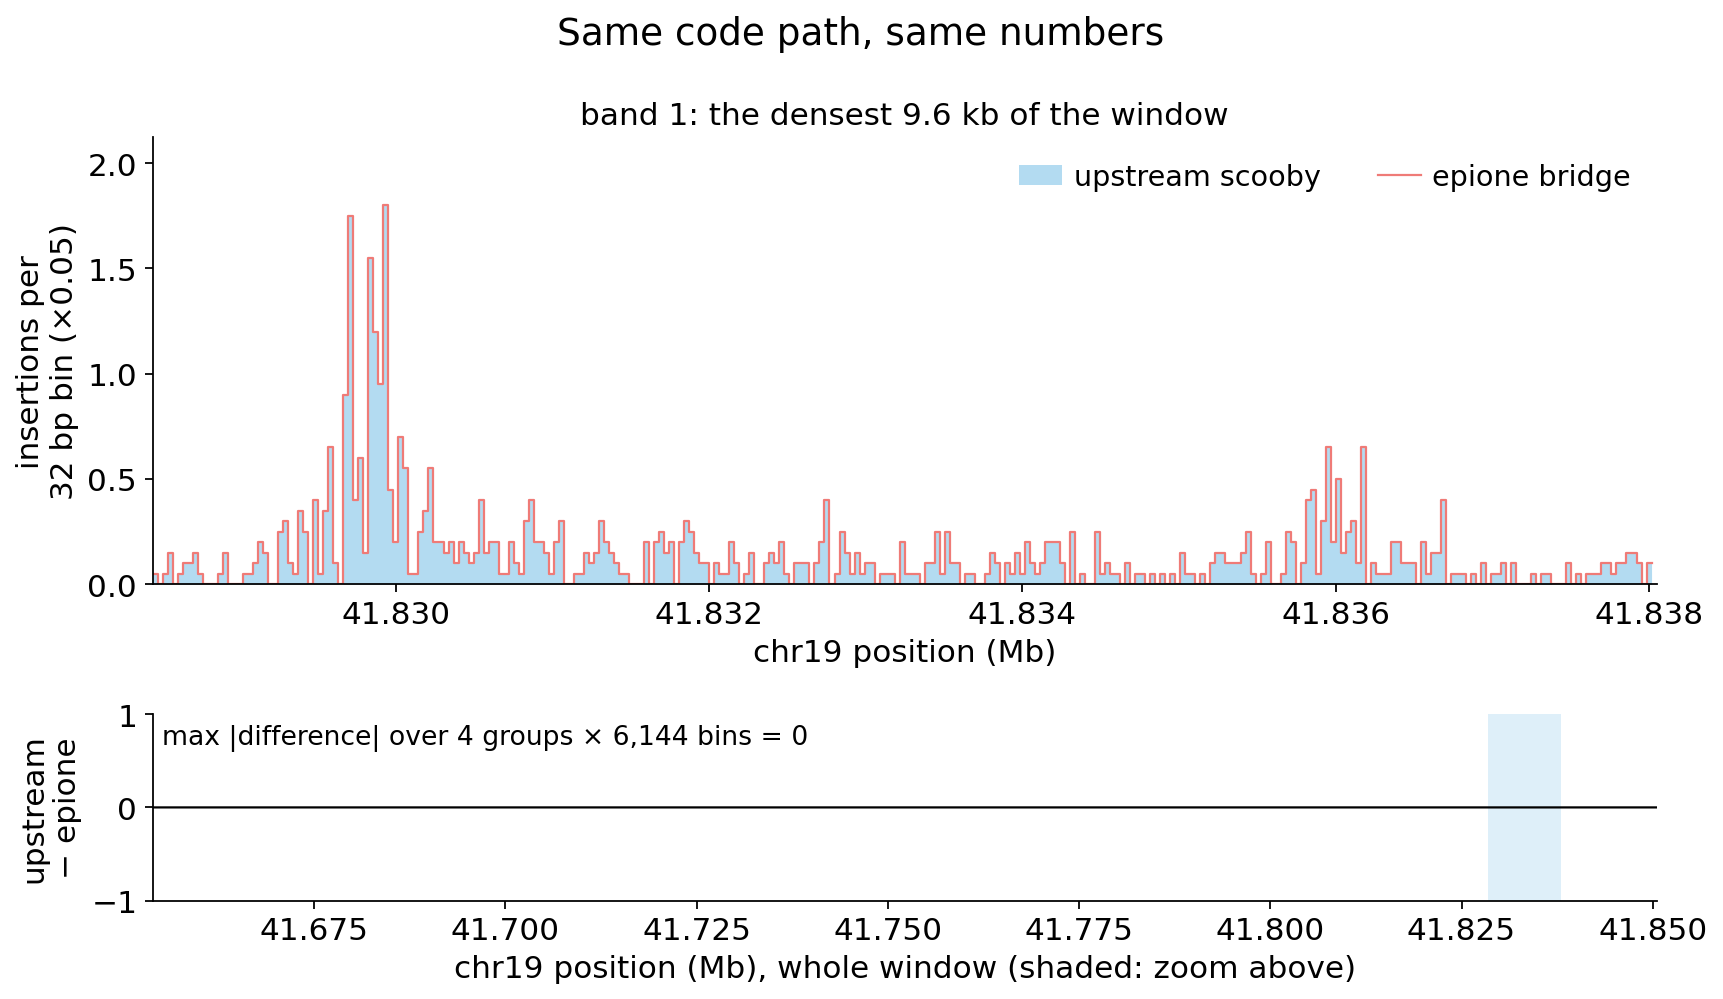

In [14]:
if HAVE_UPSTREAM:
    g = 0
    # 6,144 bins across a page is ~0.04 px per bin: two identical dense
    # series would just overplot. Zoom the overlay onto the densest 300
    # bins so both are actually resolvable, and keep the residual panel
    # over every bin so the claim still covers the whole window.
    k = 300
    roll = np.convolve(up[g], np.ones(k), 'valid')
    z0 = int(roll.argmax()); z1 = z0 + k
    xz = x[z0:z1]

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6.4),
                                 gridspec_kw={'height_ratios': [2.4, 1]})

    a1.fill_between(xz, 0, up[g][z0:z1], step='post', color=C[0], alpha=0.35,
                    lw=0, label='upstream scooby')
    a1.step(xz, mine[g][z0:z1], where='post', color=C[1], lw=1.0,
            label='epione bridge')
    a1.legend(loc='upper right', ncol=2, frameon=False, handlelength=1.5)
    a1.set_ylabel('insertions per\n32 bp bin (×0.05)')
    a1.set_xlim(xz[0], xz[-1] + 32 / 1e6)
    a1.set_ylim(0, up[g][z0:z1].max() * 1.18)
    a1.set_title(f'{names[g]}: the densest {k * 32 / 1e3:.1f} kb of the window')
    a1.set_xlabel(f'{CHROM} position (Mb)')
    a1.spines[['top', 'right']].set_visible(False)

    # Residual over every bin of the window; the shaded strip is the zoom above.
    a2.axvspan(xz[0], xz[-1] + 32 / 1e6, color=C[0], alpha=0.15, lw=0)
    a2.plot(x, (up - mine)[g], color='k', lw=1.0)
    a2.set_ylim(-1, 1); a2.set_yticks([-1, 0, 1])
    a2.set_ylabel('upstream\n− epione')
    a2.set_xlabel(f'{CHROM} position (Mb), whole window (shaded: zoom above)')
    a2.set_xlim(W0 / 1e6, (W0 + T) / 1e6)
    a2.annotate(f'max |difference| over {up.shape[0]} groups '
                f'× {up.shape[1]:,} bins = {np.abs(up - mine).max():.0f}',
                xy=(0.006, 0.95), xycoords='axes fraction', va='top',
                fontsize=12)
    a2.spines[['top', 'right']].set_visible(False)
    fig.suptitle('Same code path, same numbers')
    plt.tight_layout(); plt.show()

The conventions this pins down, each of which would silently invalidate a
benchmark if wrong: insertions at both fragment ends, the duplicate-count
column ignored, 32 bp sum-binning, and ATAC scaled by exactly `0.05` with
**no** clipping (upstream's `clip_soft` applies to RNA only).

One upstream limit found while checking this: a window ending within
`custom_read_length + 10` = 100 bp of a contig end makes upstream's trim
`dense[100:0]`, an empty array, and its pooling step then raises. The
reader returns a correct profile there, and `make_fold_bed(edge_margin=…)`
keeps windows clear of contig ends so the two stay comparable.